# <center>Taller de Aprendizaje Automático</center>
## <center>Taller 5: Clasificación binaria del Higgs con redes neuronales</center>

## Sub objetivos

Parte 2: Entrenar un modelo MLP de referencia con Keras para clasificación binaria.

Parte 3: Ajustar la arquitectura con una búsqueda manual pequeña y comparar variantes inspiradas en la guía del taller.


## Introducción

En este notebook se trabaja sobre el dataset procesado del desafío Higgs Boson. A diferencia del taller original de regresión, aquí el problema es de **clasificación binaria**: la etiqueta `Label` toma los valores `s` y `b`.

Se omite la sección de preprocesamiento antiguo y se parte directamente de los archivos ya preparados en `data/higgs-boson/processed/i1/`.

## Preparación de datos

Se cargan `X_train_processed.csv`, `y_train.csv`, `X_test_processed.csv` y `test_event_id.csv`. El dataset etiquetado se usa para armar `train/validación`, mientras que `X_test_processed` queda separado como conjunto externo sin etiquetas para inferencia final.

In [1]:
from pathlib import Path
import os

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)


def find_processed_data_dir() -> Path:
    """Busca el directorio de datos procesados desde el cwd actual."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidate = base / "data" / "higgs-boson" / "processed" / "i1"
        if candidate.exists():
            return candidate
    raise FileNotFoundError("No se encontro data/higgs-boson/processed/i1")


data_dir = find_processed_data_dir()
print(f"Data dir: {data_dir}")

I0000 00:00:1776603557.813736   10192 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1776603558.662719   10192 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/lib/python3/dist-packages/requests/__init__.py:87: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (4.0.0) doesn't match a supported version!
  warnings.warn("urllib3 ({}) or chardet ({}) doesn't match a supported "
I0000 00:00:1776603561.610619   10192 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Data dir: /home/santig14/fing/taa/1_TallerAA/data/higgs-boson/processed/i1


In [2]:
X_labeled_full = pd.read_csv(data_dir / "X_train_processed.csv")
y_labeled_full = pd.read_csv(data_dir / "y_train.csv")
X_test_processed = pd.read_csv(data_dir / "X_test_processed.csv")
test_event_id = pd.read_csv(data_dir / "test_event_id.csv")

if list(X_labeled_full.columns) != list(X_test_processed.columns):
    raise ValueError("Las columnas de train y X_test_processed no coinciden.")

if len(X_test_processed) != len(test_event_id):
    raise ValueError("La cantidad de filas de X_test_processed y test_event_id no coincide.")

X = X_labeled_full.astype(np.float32)
y = y_labeled_full["Label"].map({"b": 0, "s": 1}).astype(np.int8)
X_test = X_test_processed.astype(np.float32)

print(f"X labeled shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"X_test_processed shape: {X_test.shape}")
print(f"test_event_id shape: {test_event_id.shape}")
print("Class distribution:")
display(y.value_counts().rename(index={0: "b", 1: "s"}))
display(y.value_counts(normalize=True).rename(index={0: "b", 1: "s"}).rename("proportion"))

X labeled shape: (250000, 26)
y shape: (250000,)
X_test_processed shape: (550000, 26)
test_event_id shape: (550000, 1)
Class distribution:


Label
b    164333
s     85667
Name: count, dtype: int64

Label
b    0.657332
s    0.342668
Name: proportion, dtype: float64

## Train / validation split

Se reserva un 10% del dataset etiquetado para validación usando un split estratificado, para preservar la proporción de clases en ambos subconjuntos. `X_test_processed` no participa de este paso porque se mantiene como conjunto externo para inferencia.

In [3]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.1,
    random_state=SEED,
    stratify=y,
)

X_train_np = X_train.to_numpy(dtype=np.float32)
X_valid_np = X_valid.to_numpy(dtype=np.float32)
X_test_np = X_test.to_numpy(dtype=np.float32)
y_train_np = y_train.to_numpy(dtype=np.float32)
y_valid_np = y_valid.to_numpy(dtype=np.float32)

classes = np.array([0, 1])
class_weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train_np.astype(int))
class_weight = {int(cls): float(weight) for cls, weight in zip(classes, class_weights)}

print(f"Train shape: {X_train_np.shape}")
print(f"Valid shape: {X_valid_np.shape}")
print(f"External test shape: {X_test_np.shape}")
print(f"Class weight: {class_weight}")

Train shape: (225000, 26)
Valid shape: (25000, 26)
External test shape: (550000, 26)
Class weight: {0: 0.7606490872210954, 1: 1.4591439688715953}


## Parte 2 - Baseline MLP

La red de referencia mantiene una estructura simple: una capa oculta densa y una capa final de clasificación con `sigmoid`. Para este problema se usa `binary_crossentropy` y métricas apropiadas para clasificación binaria.

In [4]:
INPUT_DIM = X_train_np.shape[1]
BASELINE_UNITS = 32


def build_baseline_model(input_dim: int = INPUT_DIM, learning_rate: float = 1e-3) -> keras.Model:
    model = keras.Sequential([
        keras.layers.Input(shape=(input_dim,)),
        keras.layers.Dense(BASELINE_UNITS, activation="relu", kernel_initializer="he_normal"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.AUC(name="auc"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
        ],
    )
    return model


baseline_model = build_baseline_model()
baseline_model.summary()

manual_params = (INPUT_DIM + 1) * BASELINE_UNITS + (BASELINE_UNITS + 1) * 1
print(f"Parametros entrenables (manual): {manual_params}")
print(f"Parametros entrenables (Keras): {baseline_model.count_params()}")

E0000 00:00:1776603568.261727   10192 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1776603568.262165   10314 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1776603568.295456   10192 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 897 (3.50 KB)

 Trainable params: 897 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

Parametros entrenables (manual): 897
Parametros entrenables (Keras): 897


In [5]:
def make_callbacks() -> list[keras.callbacks.Callback]:
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_auc",
            mode="max",
            patience=4,
            restore_best_weights=True,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-5,
        ),
    ]

baseline_history = baseline_model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_valid_np, y_valid_np),
    epochs=20,
    batch_size=1024,
    class_weight=class_weight,
    callbacks=make_callbacks(),
    verbose=1,
)

baseline_eval = baseline_model.evaluate(X_valid_np, y_valid_np, verbose=0, return_dict=True)
print(baseline_eval)

Epoch 1/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6835 - auc: 0.7660 - loss: 0.5786 - precision: 0.5268 - recall: 0.7516 - val_accuracy: 0.7519 - val_auc: 0.8314 - val_loss: 0.5058 - val_precision: 0.6086 - val_recall: 0.7731 - learning_rate: 0.0010
Epoch 2/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7692 - auc: 0.8547 - loss: 0.4776 - precision: 0.6292 - recall: 0.7951 - val_accuracy: 0.7835 - val_auc: 0.8670 - val_loss: 0.4586 - val_precision: 0.6489 - val_recall: 0.8021 - learning_rate: 0.0010
Epoch 3/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7891 - auc: 0.8763 - loss: 0.4457 - precision: 0.6549 - recall: 0.8127 - val_accuracy: 0.7937 - val_auc: 0.8787 - val_loss: 0.4413 - val_precision: 0.6621 - val_recall: 0.8130 - learning_rate: 0.0010
Epoch 4/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7976 - auc: 0.8841 - loss: 0.4329 - precision: 0.6664 - recall: 0.8194 - val_accuracy: 0.8000 - val_auc: 0.8833 - val_loss: 0.4337 - val

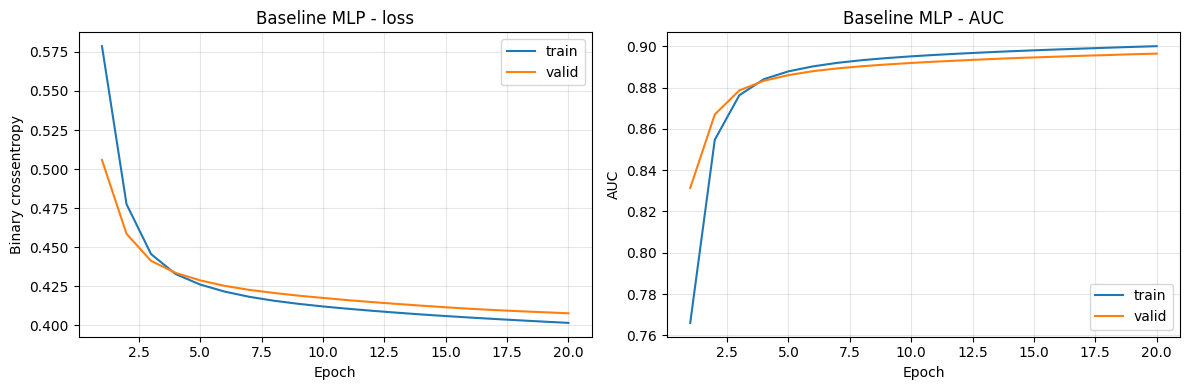

In [6]:
def plot_history(history, title: str) -> None:
    history_df = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history_df.index + 1, history_df["loss"], label="train")
    axes[0].plot(history_df.index + 1, history_df["val_loss"], label="valid")
    axes[0].set_title(f"{title} - loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Binary crossentropy")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(history_df.index + 1, history_df["auc"], label="train")
    axes[1].plot(history_df.index + 1, history_df["val_auc"], label="valid")
    axes[1].set_title(f"{title} - AUC")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("AUC")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


plot_history(baseline_history, "Baseline MLP")

## Resumen tabular del modelo

Para dejar una lectura mas directa del baseline, al final se arma una tabla con la configuracion principal del modelo y sus metricas de validacion. Tambien se muestra el historial de entrenamiento por epoca en formato tabular.

In [7]:
baseline_history_df = pd.DataFrame(baseline_history.history)

baseline_summary_df = pd.DataFrame(
    [
        {
            "input_dim": INPUT_DIM,
            "hidden_layers": 1,
            "hidden_units": BASELINE_UNITS,
            "learning_rate": 1e-3,
            "batch_size": 1024,
            "epochs_ran": len(baseline_history_df),
            "trainable_params_manual": manual_params,
            "trainable_params_keras": baseline_model.count_params(),
            **{metric: float(value) for metric, value in baseline_eval.items()},
        }
    ]
)

history_columns = [
    "loss",
    "accuracy",
    "auc",
    "precision",
    "recall",
    "val_loss",
    "val_accuracy",
    "val_auc",
    "val_precision",
    "val_recall",
]
available_history_columns = [column for column in history_columns if column in baseline_history_df.columns]

baseline_history_table = baseline_history_df[available_history_columns].copy()
baseline_history_table.index = baseline_history_table.index + 1
baseline_history_table.index.name = "epoch"

print("Resumen del baseline MLP:")
display(baseline_summary_df.round(4))

print("Historial de entrenamiento por epoca:")
display(baseline_history_table.round(4))


Resumen del baseline MLP:


,input_dim,hidden_layers,hidden_units,learning_rate,batch_size,epochs_ran,trainable_params_manual,trainable_params_keras,accuracy,auc,loss,precision,recall
0,26,1,32,0.001,1024,20,897,897,0.8133,0.8965,0.4078,0.6899,0.8269


Historial de entrenamiento por epoca:


,loss,accuracy,auc,precision,recall,val_loss,val_accuracy,val_auc,val_precision,val_recall
epoch,,,,,,,,,,
1,0.5786,0.6835,0.7660,0.5268,0.7516,0.5058,0.7519,0.8314,0.6086,0.7731
2,0.4776,0.7692,0.8547,0.6292,0.7951,0.4586,0.7835,0.8670,0.6489,0.8021
3,0.4457,0.7891,0.8763,0.6549,0.8127,0.4413,0.7937,0.8787,0.6621,0.8130
4,0.4329,0.7976,0.8841,0.6664,0.8194,0.4337,0.8000,0.8833,0.6702,0.8195
5,0.4262,0.8017,0.8879,0.6720,0.8227,0.4289,0.8020,0.8861,0.6738,0.8183
6,0.4217,0.8046,0.8903,0.6761,0.8250,0.4254,0.8044,0.8880,0.6770,0.8212
7,0.4183,0.8067,0.8920,0.6792,0.8263,0.4228,0.8064,0.8894,0.6795,0.8230
8,0.4158,0.8080,0.8933,0.6808,0.8276,0.4208,0.8062,0.8904,0.6792,0.8235
9,0.4139,0.8089,0.8943,0.6823,0.8279,0.4191,0.8063,0.8912,0.6793,0.8236
